# Ejemplo: rankFD con el sensor ultrasónico LEGO EV3

El tipo de superficie (mate/brillante) y la distancia (10, 100 y 250 cm) influyen en el error del sensor? ¿Hay interacción entre ambos factores?

Diseño: factorial 3x2 con 15 mediciones por combinación (n = 90).
Variable respuesta: error absoluto = |lectura del sensor − distancia real|.
Método Aplicado: rankFD, alternativa no paramétrica.

### Cargar los datos
Los datos utilizados son los mismos que en la segunda entrega del proyecto. Pared y distancia se definen como factores.

In [ ]:
library(rankFD)
library(ggplot2)
install.packages("car", repos = "https://cloud.r-project.org")

data_dirs <- c(file.path("data"), file.path("T4-GML", "data"))
data_dir <- data_dirs[dir.exists(data_dirs)][1]
if (is.na(data_dir)) stop("No se encontró la carpeta T4-GML/data")
data_files <- list.files(data_dir, pattern = "^Datos - Toma de datos.*\\.csv$", full.names = TRUE)
if (length(data_files) == 0) stop("No se encontraron los CSV generados para T4-GML")

datos <- do.call(rbind, lapply(data_files, read.csv, sep = ",", dec = ",", check.names = FALSE))
datos$pared <- datos$`Tipo de pared`
datos$dist <- as.numeric(datos$`Distancia de referencia (cm)`) * 10
datos$Tipo <- factor(datos$pared, levels = c("Mate", "Brillante"))
datos$dist  <- factor(datos$dist, levels = c(100, 1000, 2500),
                      labels = c("10 cm", "100 cm", "250 cm"))
str(datos)
table(datos$pared, datos$dist)

'data.frame':	90 obs. of  12 variables:
 $ ID                          : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Tipo de pared               : chr  "Mate" "Mate" "Mate" "Mate" ...
 $ Distancia de referencia (cm): num  10 10 10 10 10 100 100 100 100 100 ...
 $ Repetición                  : int  1 2 3 4 5 1 2 3 4 5 ...
 $ Lectura del sensor (cm)     : num  10.3 9.9 10.2 10.1 10.1 ...
 $ Error con signo (cm)        : num  0.3 -0.1 0.2 0.1 0.1 -0.8 0.1 0.2 -0.5 0.2 ...
 $ Error absoluto (cm)         : num  0.3 0.1 0.2 0.1 0.1 0.8 0.1 0.2 0.5 0.2 ...
 $ Error relativo (%)          : chr  "3,00%" "1,00%" "2,00%" "1,00%" ...
 $ Observaciones               : chr  "" "" "" "" ...
 $ pared                       : chr  "Mate" "Mate" "Mate" "Mate" ...
 $ dist                        : Factor w/ 3 levels "10 cm","100 cm",..: 1 1 1 1 1 2 2 2 2 2 ...
 $ Tipo                        : Factor w/ 2 levels "Mate","Brillante": 1 1 1 1 1 1 1 1 1 1 ...


           
            10 cm 100 cm 250 cm
  Brillante    15     15     15
  Mate         15     15     15

### Por qué rankFD?
Como es sabido, el ANOVA factorial exige tanto normalidad, como varianzas iguales. Shapiro-Wilk rechaza normalidad en todas sus combinaciones y Levene rechaza homogeneidad de varianzas (p = 0.04364447). Esa es la razón por la que se usa rankFD, que no requiere ninguno de los dos supuestos.

In [ ]:
datos$err <- as.numeric(datos$`Error absoluto (cm)`)
shapiro_p <- tapply(datos$err, list(datos$pared, datos$dist), function(x) shapiro.test(x)$p.value)
shapiro_p
car::leveneTest(err ~ pared * dist, data = datos, center = median)

,10 cm,100 cm,250 cm
Brillante,6.368184e-04,8.673081e-07,2.992163e-04
Mate,5.407753e-05,1.187992e-05,4.514263e-06


,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,5,2.401702,0.04364447
,84,NA,NA


### Ajustes del modelo

Primeramente se asignan rangos a las 90 observaciones recopiladas. Posteriormente se estima el efecto relativo de cada combinación, el cuál es la probabilidad de que una medición de ese grupo sea mayor que otra al azar. Si el valor llega a ser 0.5, significa que no hay efecto. Finalmente, se contrasta la hipótesis nula con el estadístico ATS.

In [11]:
mod <- rankFD(err ~ pared * dist, data = datos, CI.method = "logit", effect = "unweighted", hypothesis = "H0F", alpha = 0.05)
names(mod)
mod
mod$ANOVA.Type.Statistic

[1] "Call"                 "Descriptive"          "Wald.Type.Statistic" 
 [4] "ANOVA.Type.Statistic" "MCTP"                 "Factor.Information"  
 [7] "Covariance.Matrix"    "plotting"             "plotsci"             
[10] "output"


 
               Nonparametric Methods for General Factorial Designs      
 
 ---------------------------------------------------------------------------
 #Hypotheses: Tested in Distribution Functions 
 #Ranking Method: Pseudo-Ranks 
 #Confidence Intervals: 95 % with Logit-Transformation 
 
 
---------------------------------------------------------------------------

Call:
err ~ pared * dist

Descriptive:
      pared   dist Size Rel.Effect Std.Error  Lower  Upper
1 Brillante  10 cm   15     0.3478    0.0425 0.2697 0.4350
2 Brillante 100 cm   15     0.4181    0.0625 0.3028 0.5432
3 Brillante 250 cm   15     0.7137    0.0522 0.6019 0.8043
4      Mate  10 cm   15     0.3030    0.0404 0.2300 0.3874
5      Mate 100 cm   15     0.3767    0.0564 0.2740 0.4917
6      Mate 250 cm   15     0.8407    0.0203 0.7969 0.8766

Wald.Type.Statistic:
           Statistic df p-Value
pared         0.0977  1  0.7546
dist        113.1418  2  0.0000
pared:dist    4.3714  2  0.1124

ANOVA.Type.Statistic:
   

,Statistic,df1,df2,p-Value
pared,0.0977,1.0000,63.2897,0.7556
dist,41.6390,1.8125,63.2897,0.0000
pared:dist,1.7057,1.8125,63.2897,0.1923


### Visualizar los efectos relativos

En el siguiente gráfico, cada línea representa un tipo de pared, mientras que el eje horizontal representa las distancias. La linea punteada es el valor 0.5, por lo que si un intervalo no lo cruza, indica que se alejó del promedio. Por otro lado, si las lineas no son paralelas, hay indicio de interacción.

[1] "pared"      "dist"       "Size"       "Rel.Effect" "Std.Error" 
[6] "Lower"      "Upper"

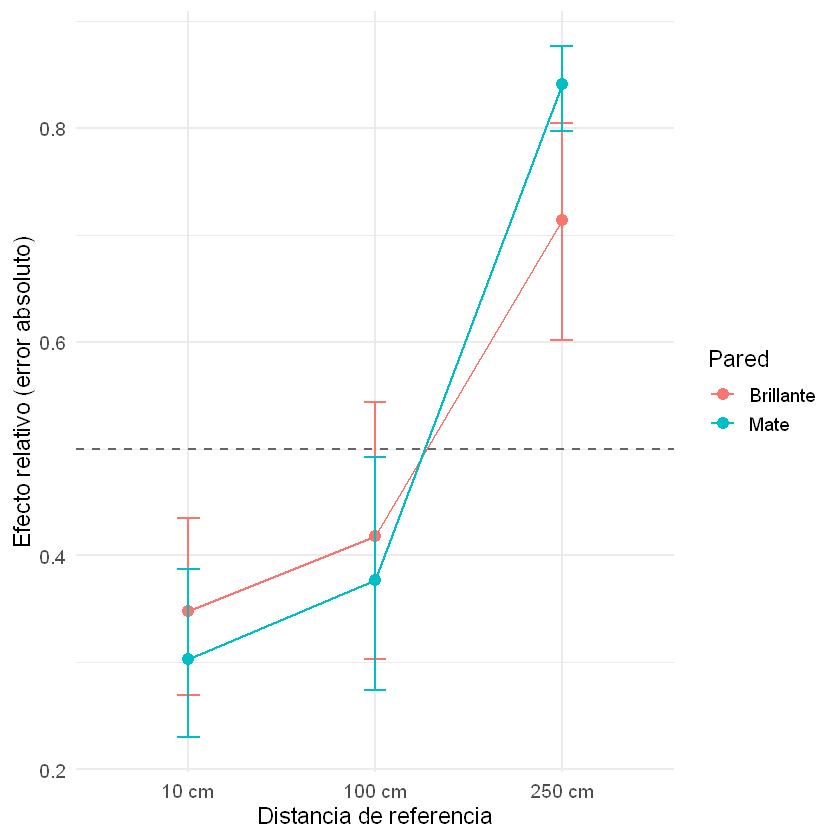

In [10]:
d <- mod$Descriptive
names(d)   # verifica nombres: factores, Rel.Effect, Lower, Upper
ggplot(d, aes(x = dist, y = Rel.Effect, color = pared, group = pared)) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "gray40") +
  geom_line() + geom_point(size = 3) +
  geom_errorbar(aes(ymin = Lower, ymax = Upper), width = 0.12) +
  labs(x = "Distancia de referencia", y = "Efecto relativo (error absoluto)",
       color = "Pared") +
  theme_minimal(base_size = 14)

### Interpretación y conclusiones

La prueba ATS muestra que la distancia sí afecta de forma significa al error absoluto. Aún así, el tipo de pared y la interacción no fueron significativos.

En cuanto a los efectos relativos, se confirma que a 10 y 100 cm los valores están por debajo de 0.5, y a 250 cm suben a 0.7137 en la pared brillante y 0.8407 en la mate. Por lo que se puede observar, ambas paredes tienen un comportamiento similar y sus intervalos se solapan. Aunque las líneas se cruzan a 250 cm, no hay evidencia suficiente de interacción, ya que con 15 mediciones por combinación, la prueba tiene poca potencia para detectarla.

Por lo que en conclusión, solo la distancia influye significativamente en el error del sensor. A 250 cm el sensor se satura debido a la salida de 255 por perdida de señal, lo que provoca empates.